# Quantification entière d'un réseau de neurones
**Application de Jacob et al. (Google, 2017), sections 1 et 2, au réseau NumPy des TP5–TP7**

**Objectif.** Un réseau entraîné calcule en flottant. Le papier montre qu'on peut faire toute l'inférence avec des **entiers 8 bits**, presque sans perte. On l'applique à notre réseau, puis on regarde **quelles couches** souffrent de la quantification, **comment** l'erreur se propage et **pourquoi**.

**Plan**
1. Le réseau et son entraînement
2. Le schéma de quantification $r = S(q-Z)$
3. Une couche 100 % entière
4. Résultat : le réseau entier contre le réseau flottant
5. Analyse de l'erreur couche par couche
6. Visualisation sur la spirale
7. Conclusion

## 1. Le réseau et son entraînement

On reprend la bibliothèque des TP : chaque couche a un `forward` (calcul de la sortie) et un `backward` (rétropropagation du gradient). Les données sont rangées **en colonnes** : $X$ est de taille $(p, n)$ pour $n$ données de dimension $p$.

- **Dense** : $y = Ax + b$, avec $\hat A = \hat y\,x^T$, $\hat b = \sum \hat y$, $\hat x = A^T\hat y$
- **ReLU6** : $y = \min(\max(x,0),6)$. C'est l'activation du papier : bornée, et réduite à un simple écrêtage en entiers.
- **Softmax + entropie croisée** : la perte, de gradient $(\text{softmax}(z) - O)/n$
- **Adam** sur mini-lots, à la place du pas fixe des TP

**Données** : chiffres manuscrits $8\times8$ (`sklearn`), 64 pixels dans $[0,1]$, 10 classes.
**Réseau** : $64 \to 128 \to 64 \to 32 \to 10$, soit 4 couches denses avec ReLU6 entre elles. Ça fait 4 couches, de quoi étudier la **propagation** de l'erreur.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

class Parameter:
    def __init__(self, data):
        self.data, self.grad = data, np.zeros_like(data)

class Dense:
    def __init__(self, p, q):                       # init de He
        self.list_params = [Parameter(np.random.randn(q, p) * np.sqrt(2 / p)), Parameter(np.zeros((q, 1)))]
    A = property(lambda self: self.list_params[0].data)
    b = property(lambda self: self.list_params[1].data)
    def forward(self, x):
        self.save = x; return self.A @ x + self.b
    def backward(self, gy):
        self.list_params[0].grad = gy @ self.save.T
        self.list_params[1].grad = gy.sum(axis=1, keepdims=True)
        return self.A.T @ gy

class ReLU6:
    list_params = []
    def phi(self, x): return np.clip(x, 0, 6)
    def forward(self, x):
        self.save = x; return self.phi(x)
    def backward(self, gy): return ((self.save > 0) & (self.save < 6)) * gy

class ReLU(ReLU6):
    def phi(self, x): return np.maximum(x, 0)
    def backward(self, gy): return (self.save > 0) * gy

class SoftmaxCE:                                     # perte : softmax + entropie croisée
    list_params = []
    def forward(self, z):
        z = z - z.max(axis=0)
        self.p = np.exp(z) / np.exp(z).sum(axis=0)
        return -np.mean(np.sum(self.D * np.log(self.p + 1e-12), axis=0))
    def backward(self, gy=1.0): return gy * (self.p - self.D) / self.D.shape[1]

class Sequential:
    def __init__(self, layers):
        self.list_layers = layers
        self.list_params = [p for L in layers for p in L.list_params]
    def forward(self, x):
        for L in self.list_layers: x = L.forward(x)
        return x
    def backward(self, gy):
        for L in reversed(self.list_layers): gy = L.backward(gy)
        return gy

def make_mlp(sizes, act=ReLU6):
    layers = []
    for i, (p, q) in enumerate(zip(sizes[:-1], sizes[1:])):
        layers.append(Dense(p, q))
        if i < len(sizes) - 2: layers.append(act())
    return Sequential(layers)

def train(net, X, Y, epochs=120, batch=64, lr=1e-3, seed=1):
    rng, loss = np.random.default_rng(seed), SoftmaxCE()
    net_a = Sequential([net, loss])
    m = [np.zeros_like(p.data) for p in net.list_params]; v = [np.zeros_like(p.data) for p in net.list_params]; t = 0
    for ep in range(epochs):
        perm = rng.permutation(X.shape[1])
        for k in range(0, X.shape[1], batch):
            idx = perm[k:k + batch]; loss.D = Y[:, idx]
            net_a.forward(X[:, idx]); net_a.backward(1.0); t += 1
            for p, mi, vi in zip(net.list_params, m, v):          # Adam
                mi[:] = 0.9 * mi + 0.1 * p.grad
                vi[:] = 0.999 * vi + 0.001 * p.grad**2
                p.data = p.data - lr * (mi / (1 - 0.9**t)) / (np.sqrt(vi / (1 - 0.999**t)) + 1e-8)

def accuracy(logits_or_pred, Y):
    pred = logits_or_pred if logits_or_pred.ndim == 1 else logits_or_pred.argmax(axis=0)
    return np.mean(pred == Y.argmax(axis=0))

def blocks(net):                                     # regroupe [Dense, activation] : 4 blocs
    out = []
    for L in net.list_layers:
        if isinstance(L, Dense): out.append([L, None])
        else: out[-1][1] = L
    return out

In [2]:
d = load_digits()
X, Y = d.data.T / 16, np.eye(10)[:, d.target]
perm = np.random.default_rng(0).permutation(X.shape[1])
Xtr, Ytr, Xte, Yte = X[:, perm[:1347]], Y[:, perm[:1347]], X[:, perm[1347:]], Y[:, perm[1347:]]

np.random.seed(1); net = make_mlp([64, 128, 64, 32, 10], ReLU6); train(net, Xtr, Ytr)
np.random.seed(1); net_relu = make_mlp([64, 128, 64, 32, 10], ReLU); train(net_relu, Xtr, Ytr)   # pour comparer en partie 5
logits_f = net.forward(Xte)
print(f"Précision test du réseau flottant (ReLU6) : {accuracy(logits_f, Yte):.3f}")

Précision test du réseau flottant (ReLU6) : 0.989


## 2. Le schéma de quantification (section 2.1)

Chaque réel $r$ est remplacé par un entier $q \in \{0,\dots,255\}$ avec une relation **affine** :

$$\boxed{r = S\,(q - Z)}$$

- $S$ (**scale**) : le pas de la grille, l'écart réel entre deux entiers voisins
- $Z$ (**zero-point**) : l'entier qui représente **exactement** le réel 0

On utilise un couple $(S, Z)$ par tableau : un pour les poids de chaque couche, un pour ses activations.

**Calcul à partir d'une plage $[a, b]$** (qu'on élargit si besoin pour qu'elle contienne 0) :
$$S = \frac{b-a}{255}, \qquad Z = \mathrm{round}\!\left(-\frac{a}{S}\right)$$
On a $Z = -a/S$ parce qu'on veut que $a$ corresponde à $q = 0$. On arrondit $Z$ pour qu'il soit entier : 0 est alors représenté sans erreur. C'est essentiel, car les ReLU produisent énormément de zéros.

**Quantifier et déquantifier :**
$$q = \mathrm{clamp}\big(\mathrm{round}(r/S) + Z,\ 0,\ 255\big), \qquad \hat r = S(q - Z)$$

| Exemple : plage $[-1, 3]$ | $S = 4/255 \approx 0{,}0157$, $Z = 64$ |
|---|---|
| $r = 0$ | $q = 64$, $\hat r = 0$ (exact) |
| $r = 1{,}5$ | $q = 160$, $\hat r = 1{,}506$ (erreur $\le S/2$) |
| $r = 5$ (hors plage) | $q = 255$, $\hat r = 2{,}996$ (écrêté) |

**Le point clé pour la suite** : $S$ dépend de la plage. Si quelques valeurs extrêmes l'étirent, le pas grandit pour **toutes** les valeurs du tableau.

In [3]:
def choose_qparams(rmin, rmax, bits=8):
    rmin, rmax = min(rmin, 0.0), max(rmax, 0.0)          # la plage doit contenir 0
    S = (rmax - rmin) / (2**bits - 1)
    Z = int(np.clip(round(-rmin / S), 0, 2**bits - 1))   # 0 réel exactement représentable
    return S, Z

def quantize(r, S, Z, bits=8):
    return np.clip(np.round(r / S) + Z, 0, 2**bits - 1).astype(np.int64)

def dequantize(q, S, Z):
    return S * (q - Z)

def fake_quant(r, rmin, rmax, bits=8):                    # arrondi sur la grille, mais en flottant
    S, Z = choose_qparams(rmin, rmax, bits)
    return dequantize(quantize(r, S, Z, bits), S, Z)

A1 = net.list_layers[0].A
S, Z = choose_qparams(A1.min(), A1.max())
err = dequantize(quantize(A1, S, Z), S, Z) - A1
print(f"Poids couche 1 : plage [{A1.min():.3f}, {A1.max():.3f}]  ->  S = {S:.5f}, Z = {Z}")
print(f"0 réel -> q = {quantize(0.0, S, Z)} -> {dequantize(quantize(0.0, S, Z), S, Z)}")
print(f"erreur max = {abs(err).max():.5f} (borne S/2 = {S/2:.5f}),  écart-type = {err.std():.5f} (bruit uniforme S/√12 = {S/12**0.5:.5f})")

Poids couche 1 : plage [-0.736, 0.758]  ->  S = 0.00586, Z = 126
0 réel -> q = 126 -> 0.0
erreur max = 0.00293 (borne S/2 = 0.00293),  écart-type = 0.00170 (bruit uniforme S/√12 = 0.00169)


## 3. Une couche 100 % entière (sections 2.2 à 2.4)

**Le produit matriciel.** On veut $r_3 = r_1 r_2$, avec $r_1 = A$ (poids) et $r_2 = X$ (activations). On remplace chaque réel par $S(q-Z)$ :

$$q_3 = Z_3 + M \sum_j (q_1 - Z_1)(q_2 - Z_2), \qquad M = \frac{S_1 S_2}{S_3}$$

Tout est entier **sauf $M$**. Il est calculé hors ligne et écrit $M = M_0 \cdot 2^{-n}$, avec $M_0 \in [0{,}5;1)$ stocké en entier 32 bits. Multiplier par $M$ revient alors à une multiplication entière suivie d'un décalage de $n$ bits.

**Les zero-points sans surcoût.** En développant le produit (éq. 7), le cœur du calcul est $\sum_j q_1 q_2$ sur les entiers bruts (`int32 += uint8 × uint8`). Les termes avec $Z$ ne demandent que des sommes de lignes et de colonnes.

**Une couche complète :**
```
  qx (uint8)
    │  1. accumulation : acc = qW·qx − Z_in·Σqw − Z_W·Σqx + p·Z_W·Z_in + qb     int32
    │  2. mise à l'échelle : acc × M  (multiplication entière + décalage)       int32
    │  3. + Z_out                                                              int32
    │  4. clamp(·, 0, 255)  = cast vers 8 bits                                 uint8
    ▼  5. ReLU6 = clamp(·, q(0), q(6))                                         uint8
  qy (uint8)
```
- Le **biais** est quantifié en int32 avec l'échelle $S_W S_{in}$, celle de l'accumulateur : on l'ajoute directement.
- La **mise à l'échelle** est un changement d'unité : on passe de l'échelle $S_W S_{in}$ (minuscule) à l'échelle de sortie $S_{out}$.
- Les plages des activations sont **calibrées** : on fait passer les données d'entraînement dans le réseau flottant et on relève le min et le max à la sortie de chaque couche.

In [4]:
def quantize_multiplier(M):                       # M = M0 * 2^-31 * 2^-n, M0 entier dans [2^30, 2^31)
    mant, exp = np.frexp(M)                       # M = mant * 2^exp, mant dans [0.5, 1)
    return int(round(mant * 2**31)), -int(exp)

def multiply_by_M(acc, M0, n):
    x = acc * M0                                  # produit 64 bits
    x = np.sign(x) * ((np.abs(x) + 2**30) >> 31)  # multiplication virgule fixe par M0 (arrondi)
    if n <= 0: return x << -n                     # cas rare M >= 1
    return np.sign(x) * ((np.abs(x) + (1 << (n - 1))) >> n)   # décalage de n bits (arrondi au plus proche)

class QDense:
    # Dense + biais + ReLU6, 100 % entière. Toutes les constantes sont calculées ici, hors ligne.
    def __init__(self, dense, S_in, Z_in, S_out, Z_out, act, bits_w=8, bits_a=8):
        A, b = dense.A, dense.b
        self.S_W, self.Z_W = choose_qparams(A.min(), A.max(), bits_w)
        self.qW = quantize(A, self.S_W, self.Z_W, bits_w)                 # poids uint8
        self.qb = np.round(b / (self.S_W * S_in)).astype(np.int64)        # biais int32
        self.M = self.S_W * S_in / S_out
        self.M0, self.n = quantize_multiplier(self.M)
        self.sum_w = self.qW.sum(axis=1, keepdims=True)                   # hors ligne (éq. 8)
        self.Z_in, self.S_out, self.Z_out, self.p = Z_in, S_out, Z_out, A.shape[1]
        self.qmax = 2**bits_a - 1
        self.lo = Z_out if act is not None else 0                          # ReLU : q >= q(0)
        self.hi = min(self.qmax, round(6 / S_out) + Z_out) if type(act) is ReLU6 else self.qmax   # ReLU6 : q <= q(6)

    def forward(self, qx):
        acc = (self.qW @ qx - self.Z_in * self.sum_w - self.Z_W * qx.sum(axis=0)
               + self.p * self.Z_W * self.Z_in + self.qb)                   # 1. int32
        assert np.abs(acc).max() < 2**31
        y = multiply_by_M(acc, self.M0, self.n) + self.Z_out                # 2-3.
        return np.clip(np.clip(y, 0, self.qmax), self.lo, self.hi)          # 4-5.

def calibrate(net, X):                            # plages min/max de l'entrée et de la sortie de chaque bloc
    ranges, z = [], X
    for dense, act in blocks(net):
        out = dense.forward(z)
        if act: out = act.phi(out)
        ranges.append({"in": (z.min(), z.max()), "out": (out.min(), out.max())})
        z = out
    return ranges

class QuantizedNet:
    def __init__(self, net, X_calib, bits_w=8, bits_a=8):
        self.ranges = calibrate(net, X_calib)
        self.S_in, self.Z_in = choose_qparams(*self.ranges[0]["in"], 8)    # entrée sur 8 bits (capteur)
        S, Z, self.layers = self.S_in, self.Z_in, []
        for (dense, act), rg in zip(blocks(net), self.ranges):
            So, Zo = choose_qparams(*rg["out"], bits_a)
            self.layers.append(QDense(dense, S, Z, So, Zo, act, bits_w, bits_a))
            S, Z = So, Zo
    def forward_int(self, X):
        q = quantize(X, self.S_in, self.Z_in)    # seule conversion float -> int
        for L in self.layers: q = L.forward(q)
        return q                                  # logits entiers
    def predict(self, X):
        return self.forward_int(X).argmax(axis=0) # S > 0 : l'argmax des entiers = l'argmax des réels

# test de la multiplication entière
acc = np.random.default_rng(0).integers(-2**24, 2**24, 100_000)
M0, n = quantize_multiplier(0.0123)
print("écart max avec round(acc × M) :", np.abs(multiply_by_M(acc, M0, n) - np.round(acc * 0.0123)).max())

écart max avec round(acc × M) : 1.0


## 4. Résultat : le réseau entier contre le réseau flottant

In [5]:
qnet = QuantizedNet(net, Xtr)
pred_f, pred_q = logits_f.argmax(axis=0), qnet.predict(Xte)
print(f"Précision flottante      : {accuracy(pred_f, Yte):.4f}")
print(f"Précision entière 8 bits : {accuracy(pred_q, Yte):.4f}")
print(f"Décisions différentes    : {np.sum(pred_f != pred_q)} sur {len(pred_f)}")
n_float = sum(p.data.size for p in net.list_params) * 4
n_int = sum(L.qW.size + 4 * L.qb.size + 8 for L in qnet.layers)
print(f"Taille du modèle         : {n_float/1024:.1f} Ko (float32) -> {n_int/1024:.1f} Ko (÷{n_float/n_int:.1f})\n")

print("bloc   forme      S_W      Z_W   S_out    Z_out   M          n")
for i, L in enumerate(qnet.layers):
    print(f"{i+1:<6} {str(L.qW.shape):<10} {L.S_W:.5f}  {L.Z_W:<4}  {L.S_out:.5f}  {L.Z_out:<5}  {L.M:.6f}   {L.n}")

Précision flottante      : 0.9889
Précision entière 8 bits : 0.9889
Décisions différentes    : 0 sur 450
Taille du modèle         : 74.2 Ko (float32) -> 19.3 Ko (÷3.9)

bloc   forme      S_W      Z_W   S_out    Z_out   M          n
1      (128, 64)  0.00586  126   0.01263  0      0.001818   9
2      (64, 128)  0.00471  134   0.02353  0      0.002528   8
3      (32, 64)   0.00602  136   0.02353  0      0.006023   7
4      (10, 32)   0.00671  145   0.15683  130    0.001007   9


**Lecture.**
- À 8 bits, le réseau entier prend **les mêmes décisions** que le réseau flottant, et il est **près de 4 fois plus petit**.
- Tous les $M$ sont dans $(0,1)$, comme l'annonce le papier.
- Après une ReLU6, $Z_{out} = 0$ : le réel 0 est l'entier 0. Seuls les logits (bloc 4), qui sont signés, ont un zero-point non nul.
- L'écrêtage ReLU6 ne fait en pratique rien de plus que le cast vers $[0,255]$ : la plage de sortie a été calibrée après l'activation, il est donc déjà inclus.

## 5. Analyse de l'erreur couche par couche

8 bits est très confortable. Pour voir où le réseau souffre, on baisse le nombre de bits. Pour les analyses fines (quantifier une seule couche, seulement les poids…), on utilise une **simulation en flottant** : poids et activations sont arrondis sur leur grille par `fake_quant`, le reste est du calcul flottant ordinaire. Elle reproduit l'inférence entière à 1 pas d'arrondi près (vérifié ci-dessous).

**Mesure : le SQNR** (rapport signal sur bruit de quantification) à la sortie du bloc $\ell$ :
$$\mathrm{SQNR}_\ell = 10\log_{10}\frac{\|a_\ell\|^2}{\|\hat a_\ell - a_\ell\|^2} \text{ dB}$$
Plus c'est haut, mieux c'est. Chaque bit en plus vaut environ +6 dB.

- **Erreur cumulée** : tout le réseau est quantifié. La couche $\ell$ reçoit une entrée déjà abîmée.
- **Erreur locale** : la couche $\ell$ reçoit l'entrée flottante exacte. On ne voit que l'erreur qu'elle crée elle-même.

Simulation 8 bits vs inférence entière : décisions identiques à 100.0%



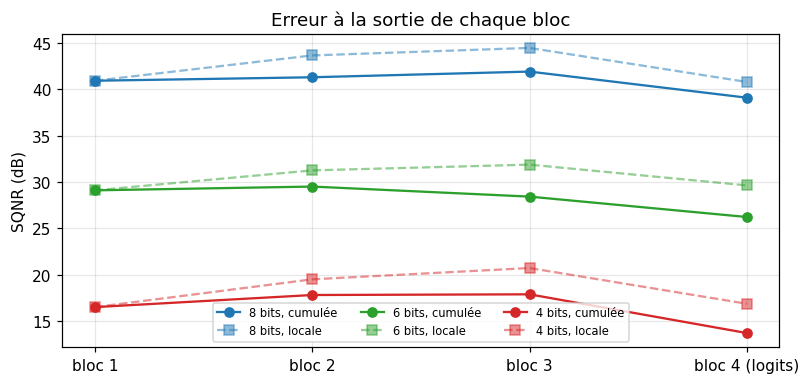

In [6]:
def sim_forward(net, X, ranges, wbits, abits, start=0):
    # Simulation flottante. wbits / abits : listes par bloc (None = pas de quantification).
    z, S_x = X, None
    if start == 0:
        S_x = choose_qparams(*ranges[0]["in"], 8)[0]; z = fake_quant(X, *ranges[0]["in"], 8)
    elif abits[start - 1]:
        S_x = choose_qparams(*ranges[start - 1]["out"], abits[start - 1])[0]
        z = fake_quant(X, *ranges[start - 1]["out"], abits[start - 1])
    outs = []
    for i, (dense, act) in list(enumerate(blocks(net)))[start:]:
        A, b = dense.A, dense.b
        if wbits[i]:
            S_W = choose_qparams(A.min(), A.max(), wbits[i])[0]
            A = fake_quant(A, A.min(), A.max(), wbits[i])
            if S_x: b = np.round(b / (S_W * S_x)) * S_W * S_x
        z = A @ z + b
        if act: z = act.phi(z)
        if abits[i]:
            S_x = choose_qparams(*ranges[i]["out"], abits[i])[0]; z = fake_quant(z, *ranges[i]["out"], abits[i])
        else: S_x = None
        outs.append(z)
    return outs

def float_outputs(net, X):
    outs, z = [], X
    for dense, act in blocks(net):
        z = dense.forward(z); z = act.phi(z) if act else z; outs.append(z)
    return outs

sqnr = lambda a, ah: 10 * np.log10(np.sum(a**2) / max(np.sum((ah - a)**2), 1e-30))
ranges, f_outs, nb = calibrate(net, Xtr), float_outputs(net, Xte), 4

print("Simulation 8 bits vs inférence entière : décisions identiques à",
      f"{np.mean(sim_forward(net, Xte, ranges, [8]*nb, [8]*nb)[-1].argmax(0) == pred_q):.1%}\n")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for bits, c in [(8, "tab:blue"), (6, "tab:green"), (4, "tab:red")]:
    cum = [sqnr(a, ah) for a, ah in zip(f_outs, sim_forward(net, Xte, ranges, [bits]*nb, [bits]*nb))]
    loc = [sqnr(f_outs[l], sim_forward(net, Xte if l == 0 else f_outs[l-1], ranges, [bits]*nb, [bits]*nb, start=l)[0])
           for l in range(nb)]
    ax.plot(range(1, 5), cum, "o-", c=c, label=f"{bits} bits, cumulée")
    ax.plot(range(1, 5), loc, "s--", c=c, alpha=0.5, label=f"{bits} bits, locale")
ax.set_xticks(range(1, 5)); ax.set_xticklabels(["bloc 1", "bloc 2", "bloc 3", "bloc 4 (logits)"])
ax.set_ylabel("SQNR (dB)"); ax.legend(ncol=3, fontsize=7.5); ax.set_title("Erreur à la sortie de chaque bloc")
plt.tight_layout(); plt.show()

**Comment l'erreur se propage.**
- Les courbes sont espacées d'environ 12 dB pour 2 bits : on retrouve les **6 dB par bit**. L'erreur se comporte comme un bruit d'arrondi uniforme.
- Au bloc 1, locale et cumulée coïncident, puisque l'entrée est la même (l'image).
- Dès le bloc 2, la cumulée passe 2 à 3 dB sous la locale : chaque couche **ajoute son bruit** à celui qu'elle hérite. L'erreur s'accumule le long du réseau.

**Pourquoi certaines couches perdent plus que d'autres.** Le pas $S$ dépend de la **plage**, alors que le signal dépend de la **valeur typique** (RMS). L'erreur relative d'une couche est donc gouvernée par le **facteur de crête**
$$\kappa = \frac{\text{plage}}{\text{valeur RMS}}$$
de ses poids et de ses entrées, et non par sa taille. Quelques valeurs extrêmes, ou une entrée pleine de zéros, étirent la plage sans augmenter le signal.

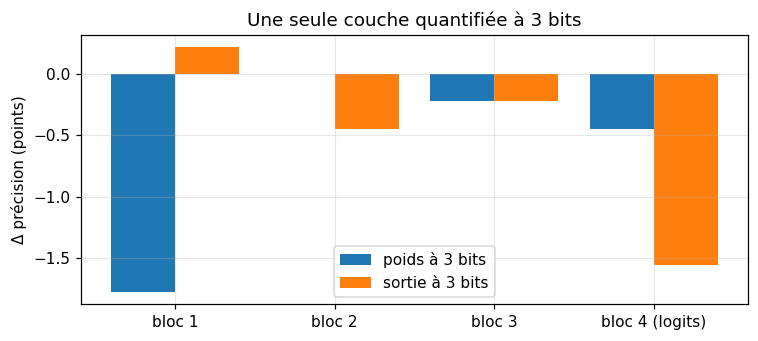

bloc   κ poids   κ entrée
1      7.6       2.1
2      8.0       4.2
3      7.1       3.4
4      5.2       1.8


In [7]:
crest = lambda r: (r.max() - min(r.min(), 0)) / np.sqrt(np.mean(r**2))
base = accuracy(logits_f, Yte)
drop_w, drop_a = [], []
for l in range(nb):                       # une seule couche quantifiée à 3 bits, le reste en flottant
    w = [None]*nb; w[l] = 3
    a = [None]*nb; a[l] = 3
    drop_w.append(100 * (accuracy(sim_forward(net, Xte, ranges, w, [None]*nb)[-1], Yte) - base))
    drop_a.append(100 * (accuracy(sim_forward(net, Xte, ranges, [None]*nb, a)[-1], Yte) - base))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(np.arange(nb) - 0.2, drop_w, 0.4, label="poids à 3 bits")
ax.bar(np.arange(nb) + 0.2, drop_a, 0.4, label="sortie à 3 bits")
ax.set_xticks(range(nb)); ax.set_xticklabels(["bloc 1", "bloc 2", "bloc 3", "bloc 4 (logits)"])
ax.set_ylabel("Δ précision (points)"); ax.legend(); ax.set_title("Une seule couche quantifiée à 3 bits")
plt.tight_layout(); plt.show()

print("bloc   κ poids   κ entrée")
for l, (dense, _) in enumerate(blocks(net)):
    print(f"{l+1:<6} {crest(dense.A):<9.1f} {crest(Xte if l == 0 else f_outs[l-1]):.1f}")

**Quelles couches souffrent le plus.**
- **Bloc 1, ses poids** : c'est la couche la plus sensible. Ses poids ont l'un des plus grands facteurs de crête, et son erreur traverse ensuite les trois couches suivantes.
- **Bloc 4, sa sortie (les logits)** : à 3 bits, il n'y a que 8 niveaux pour 10 classes. Plusieurs classes tombent sur le même entier et l'argmax devient un tirage. Rien n'absorbe l'erreur après cette couche : on garde souvent la dernière couche en plus haute précision.
- **Blocs 2 et 3** : très robustes. Ils sont redondants (128 et 64 neurones pour une information de faible dimension).

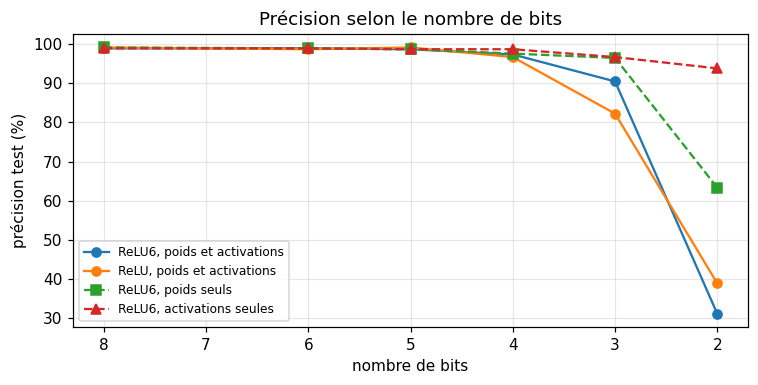

plage max des activations cachées  ReLU6 : [3.2, 6.0, 6.0]   ReLU : [3.4, 9.5, 20.2]


In [8]:
bit_list = [8, 6, 5, 4, 3, 2]
curves = {
    "ReLU6, poids et activations": [accuracy(QuantizedNet(net, Xtr, b, b).predict(Xte), Yte) for b in bit_list],
    "ReLU, poids et activations":  [accuracy(QuantizedNet(net_relu, Xtr, b, b).predict(Xte), Yte) for b in bit_list],
    "ReLU6, poids seuls":          [accuracy(sim_forward(net, Xte, ranges, [b]*nb, [None]*nb)[-1], Yte) for b in bit_list],
    "ReLU6, activations seules":   [accuracy(sim_forward(net, Xte, ranges, [None]*nb, [b]*nb)[-1], Yte) for b in bit_list],
}
fig, ax = plt.subplots(figsize=(7, 3.6))
for (k, v), s in zip(curves.items(), ["o-", "o-", "s--", "^--"]):
    ax.plot(bit_list, 100 * np.array(v), s, label=k)
ax.invert_xaxis(); ax.set_xlabel("nombre de bits"); ax.set_ylabel("précision test (%)"); ax.legend(fontsize=8)
ax.set_title("Précision selon le nombre de bits"); plt.tight_layout(); plt.show()
print("plage max des activations cachées  ReLU6 :", [round(float(r["out"][1]), 1) for r in calibrate(net, Xtr)[:-1]],
      "  ReLU :", [round(float(r["out"][1]), 1) for r in calibrate(net_relu, Xtr)[:-1]])

**Deux conclusions du papier retrouvées.**
- **Les poids sont plus sensibles que les activations** : à 2 bits, des poids quantifiés détruisent le réseau, alors que des activations quantifiées le dégradent peu. Avec 4 niveaux pour une distribution en cloche, presque tous les poids tombent sur la même valeur. Les activations ReLU6, elles, sont surtout des 0, qui restent exacts.
- **ReLU6 résiste mieux que ReLU** : à 3 bits, le réseau ReLU tombe à ~82 % contre ~90 % pour ReLU6 (à 2 bits, les deux sont détruits). Les activations ReLU montent jusqu'à environ 20, contre 6 au maximum pour ReLU6. La plage est plus large, donc le pas $S$ est plus grossier pour les mêmes valeurs typiques. C'est encore l'effet du facteur de crête.

## 6. Visualisation sur la spirale (TP7)

Un réseau $2 \to 32 \to 32 \to 3$ (ReLU6), puis ses zones de décision en flottant et en entier à 8, 4, 3 et 2 bits.

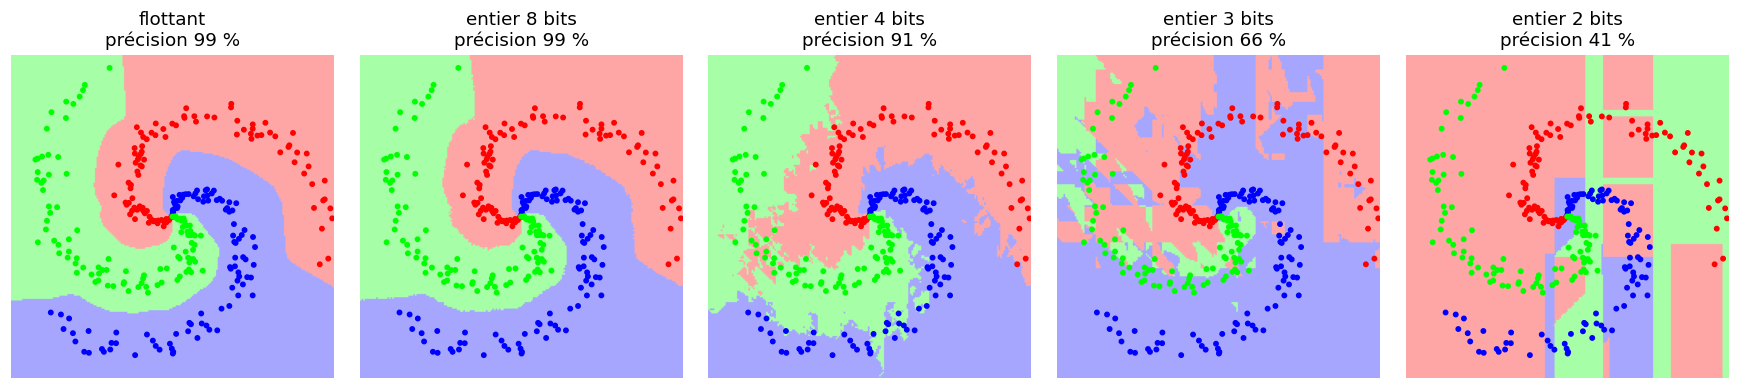

In [9]:
def make_spiral(n0=100, seed=0):
    rng = np.random.default_rng(seed); X, Y = np.zeros((2, 3*n0)), np.zeros((3, 3*n0))
    for j in range(3):
        i, r = np.arange(n0*j, n0*(j+1)), np.linspace(0, 1, n0)
        t = np.linspace(4*j, 4*(j+1), n0) + rng.normal(0, 0.2, n0)
        X[0, i], X[1, i], Y[j, i] = r*np.sin(t), r*np.cos(t), 1
    return X, Y

Xs, Ys = make_spiral()
np.random.seed(3); net_s = make_mlp([2, 32, 32, 3], ReLU6); train(net_s, Xs, Ys, epochs=1500, lr=3e-3, seed=3)
t = np.linspace(-1, 1, 200); G = np.vstack([a.ravel() for a in np.meshgrid(t, t)])

fig, axs = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, b in zip(axs, [None, 8, 4, 3, 2]):
    if b is None: pg, ps, title = net_s.forward(G).argmax(0), net_s.forward(Xs), "flottant"
    else:
        qn = QuantizedNet(net_s, np.hstack([Xs, G]), b, b)
        pg, ps, title = qn.predict(G), qn.predict(Xs), f"entier {b} bits"
    ax.imshow(pg.reshape(200, 200), origin="lower", extent=[-1, 1, -1, 1], cmap="brg", alpha=0.35)
    ax.scatter(Xs[0], Xs[1], c=Ys.argmax(0), cmap="brg", s=8)
    ax.set_title(f"{title}\nprécision {100*accuracy(ps, Ys):.0f} %"); ax.axis("off")
plt.tight_layout(); plt.show()

À 8 bits, rien ne change. En dessous, la frontière se pixellise puis s'effondre, beaucoup plus vite que sur les chiffres. Avec 2 entrées seulement et une frontière très fine, le réseau n'a **aucune redondance** pour absorber le bruit. La robustesse à la quantification dépend autant de la **tâche** que du réseau. C'est pour ça que le papier insiste pour tester sur des réseaux déjà compacts (MobileNet) plutôt que sur des réseaux surdimensionnés.

## 7. Conclusion

**Ce qu'on a fait**
- On a implémenté le schéma du papier : $r = S(q-Z)$ avec 0 exact, produit matriciel en `int32 += uint8 × uint8`, multiplicateur $M = M_0 2^{-n}$ en entiers, biais int32, ReLU6 réduite à un écrêtage.
- On a obtenu une inférence **100 % entière**, avec les **mêmes décisions** que le réseau flottant à 8 bits, pour un modèle **~4× plus petit**.

**Ce qu'on a appris sur l'erreur**
- L'erreur de quantification se comporte comme un **bruit d'arrondi** (≈ 6 dB par bit) qui **s'accumule** de couche en couche.
- Une couche souffre selon son **facteur de crête** (plage / valeur typique), pas selon sa taille.
- Les plus touchées : la **première couche** (son erreur traverse tout le réseau) et la **dernière** (peu de niveaux pour départager les classes).
- **Poids plus sensibles qu'activations**, **ReLU6 meilleure que ReLU** : deux conclusions du papier retrouvées.

**Limites et suite**
- NumPy n'accélère pas les entiers : le gain de vitesse du papier vient du matériel (instructions SIMD 8 bits). Ici, seul le gain mémoire est mesuré.
- On a quantifié **après** l'entraînement. La section 3 du papier entraîne le réseau **avec** l'arrondi simulé (*quantization-aware training*). Notre `sim_forward` en est déjà la passe avant : c'est la suite naturelle pour récupérer la précision à 3-4 bits.
- Une échelle **par neurone de sortie** plutôt que par matrice limiterait l'effet des valeurs extrêmes.